# CELL 1: Setup: Mount Drive & Define Paths

In [1]:
!pip install -q transformers accelerate bitsandbytes peft

from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_ROOT = '/content/drive/MyDrive/Bengali Paraphrasing'
PROCESSED_DIR = f'{PROJECT_ROOT}/processed_data'
CHECKPOINT_DIR = f'{PROJECT_ROOT}/checkpoints/tigerllm'
os.makedirs(f'{CHECKPOINT_DIR}/rolling', exist_ok=True)
os.makedirs(f'{CHECKPOINT_DIR}/best_model', exist_ok=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 MB 19.0 MB/s eta 0:00:00
Mounted at /content/drive


# CELL 2: Download Base Model Files (one-time, direct wget)

In [ ]:
LOCAL_MODEL_DIR = '/content/tigerllm_manual_download'
os.makedirs(LOCAL_MODEL_DIR, exist_ok=True)

base_url = "https://huggingface.co/md-nishat-008/TigerLLM-1B-it/resolve/main"
files_needed = [
    "config.json", "generation_config.json", "model.safetensors",
    "tokenizer.json", "tokenizer_config.json", "special_tokens_map.json",
    "added_tokens.json", "chat_template.jinja",
]

for fname in files_needed:
    url = f"{base_url}/{fname}"
    out_path = os.path.join(LOCAL_MODEL_DIR, fname)
    print(f"Downloading {fname}...")
    !wget "{url}" -O "{out_path}"

print("\nDone. Files present:")
for fname in os.listdir(LOCAL_MODEL_DIR):
    size = os.path.getsize(os.path.join(LOCAL_MODEL_DIR, fname))
    print(f"  {fname}: {size/(1024*1024):.2f} MB")

--2026-07-22 05:45:38--  https://huggingface.co/md-nishat-008/TigerLLM-1B-it/resolve/main/config.json
Resolving huggingface.co (huggingface.co)... 3.165.160.61, 3.165.160.59, 3.165.160.12, ...
Connecting to huggingface.co (huggingface.co)|3.165.160.61|:443... connected.
HTTP request sent, awaiting response... 307 Temporary Redirect
Location: /api/resolve-cache/models/md-nishat-008/TigerLLM-1B-it/bc84e6d99559f05470324150444b63e702d3dd53/config.json?%2Fmd-nishat-008%2FTigerLLM-1B-it%2Fresolve%2Fmain%2Fconfig.json=&etag=%221c36dcad6133eba3f231e8bef42f6b753d77dc21%22 [following]
--2026-07-22 05:45:38--  https://huggingface.co/api/resolve-cache/models/md-nishat-008/TigerLLM-1B-it/bc84e6d99559f05470324150444b63e702d3dd53/config.json?%2Fmd-nishat-008%2FTigerLLM-1B-it%2Fresolve%2Fmain%2Fconfig.json=&etag=%221c36dcad6133eba3f231e8bef42f6b753d77dc21%22
Reusing existing connection to huggingface.co:443.
HTTP request sent, awaiting response... 200 OK
Length: 1591 (1.6K) [text/plain]
Saving to: ‘/c

# CELL 3: Load Model (4-bit QLoRA), Tokenizer, Verify, Cache to Drive

In [2]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BASE_MODEL_CACHE = f'{PROJECT_ROOT}/base_model_cache/tigerllm'

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_CACHE)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_CACHE, quantization_config=bnb_config, device_map={"": 0}
)
model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    r=16, lora_alpha=32,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

MAX_LENGTH = 160  # justified by percentile check on full formatted sequences

test = "সেখানেও কিছু জটিলতা আছে।"
check_ids = tokenizer(test, add_special_tokens=False)['input_ids']
assert tokenizer.decode(check_ids, skip_special_tokens=True).strip() == test.strip()
print("Tokenization verified clean.")

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

trainable params: 13,045,760 || all params: 1,012,931,712 || trainable%: 1.2879
Tokenization verified clean.


# CELL 4: Load Cleaned Dataset (100K subset, same as other models)

In [3]:
import pandas as pd
from datasets import Dataset

train_df = pd.read_parquet(os.path.join(PROCESSED_DIR, 'train_subset_100k.parquet'))
val_df = pd.read_parquet(os.path.join(PROCESSED_DIR, 'validation_subset_5k.parquet'))

train_ds = Dataset.from_pandas(train_df[['source', 'target']])
val_ds = Dataset.from_pandas(val_df[['source', 'target']])
print(train_ds, val_ds)

Dataset({
    features: ['source', 'target'],
    num_rows: 100000
}) Dataset({
    features: ['source', 'target'],
    num_rows: 5000
})


## token-length verification cell

In [ ]:
import numpy as np
from tqdm import tqdm

INSTRUCTION = "নিচের বাক্যটি ভিন্নভাবে, একই অর্থ বজায় রেখে লিখুন।"

def get_full_sequence_length(source, target):
    messages = [{"role": "user", "content": f"{INSTRUCTION}\n\n{source}"}]
    prompt_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    full_text = prompt_text + target + tokenizer.eos_token
    return len(tokenizer(full_text, add_special_tokens=False)['input_ids'])

# Sample a representative subset for speed (measuring all 100K would be slow token-by-token)
sample_size = 5000
sample_df = train_df.sample(n=sample_size, random_state=42)

lengths = []
for _, row in tqdm(sample_df.iterrows(), total=sample_size):
    lengths.append(get_full_sequence_length(row['source'], row['target']))

lengths = np.array(lengths)

print("=== Full formatted sequence length (instruction + source + target) ===")
print(f"Mean:    {lengths.mean():.1f}")
print(f"Median:  {np.median(lengths):.1f}")
print(f"Max:     {lengths.max()}")
print(f"90th percentile: {np.percentile(lengths, 90):.1f}")
print(f"95th percentile: {np.percentile(lengths, 95):.1f}")
print(f"99th percentile: {np.percentile(lengths, 99):.1f}")

for ml in [96, 128, 160, 192, 224, 256]:
    pct_truncated = (lengths > ml).mean() * 100
    print(f"max_length={ml}: {pct_truncated:.3f}% of sequences would be truncated")

100%|██████████| 5000/5000 [00:02<00:00, 2323.54it/s]

=== Full formatted sequence length (instruction + source + target) ===
Mean:    62.2
Median:  59.0
Max:     216
90th percentile: 86.0
95th percentile: 96.0
99th percentile: 117.0
max_length=96: 4.980% of sequences would be truncated
max_length=128: 0.460% of sequences would be truncated
max_length=160: 0.060% of sequences would be truncated
max_length=192: 0.020% of sequences would be truncated
max_length=224: 0.000% of sequences would be truncated
max_length=256: 0.000% of sequences would be truncated


# CELL 5: Preprocessing (Chat Template + Label Masking) → Tokenize Dataset

In [4]:
INSTRUCTION = "নিচের বাক্যটি ভিন্নভাবে, একই অর্থ বজায় রেখে লিখুন।"

def preprocess(example):
    messages = [
        {"role": "user", "content": f"{INSTRUCTION}\n\n{example['source']}"},
    ]
    prompt_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    full_text = prompt_text + example['target'] + tokenizer.eos_token

    prompt_ids = tokenizer(prompt_text, add_special_tokens=False)['input_ids']
    full_ids = tokenizer(full_text, add_special_tokens=False, truncation=True, max_length=MAX_LENGTH)['input_ids']

    labels = full_ids.copy()
    prompt_len = min(len(prompt_ids), len(full_ids))
    labels[:prompt_len] = [-100] * prompt_len  # only compute loss on the generated response, not the prompt

    return {
        'input_ids': full_ids,
        'attention_mask': [1] * len(full_ids),
        'labels': labels,
    }

train_tok = train_ds.map(preprocess, remove_columns=['source', 'target'])
val_tok = val_ds.map(preprocess, remove_columns=['source', 'target'])
print(train_tok[0])
print("Decoded check:", tokenizer.decode(train_tok[0]['input_ids'], skip_special_tokens=False))

Map:   0%|          | 0/100000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

{'input_ids': [2, 105, 2364, 107, 4669, 43952, 114245, 2012, 51394, 8491, 236764, 30081, 16190, 130694, 34340, 28562, 5799, 236890, 108, 52096, 20606, 4302, 5634, 56171, 62750, 57937, 2012, 15671, 75047, 83566, 124500, 4156, 106, 107, 105, 4368, 107, 52096, 4302, 20606, 5634, 4026, 3394, 174014, 57937, 75047, 83566, 7318, 3611, 236890, 106], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'labels': [-100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, 52096, 4302, 20606, 5634, 4026, 3394, 174014, 57937, 75047, 83566, 7318, 3611, 236890, 106]}
Decoded check: <bos><start_of_turn>user
নিচের বাক্যটি ভিন্নভাবে, একই অর্থ বজায় রেখে লিখুন।

কিন্তু নতুন এই ঘড়ি ফোন ধারণাটি তখন বাজারে জনপ্রিয় হয়নি ।<end_

# CELL 6: Sanity Check: Confirm Clean Loss (No NaN)

In [5]:
model.eval()
with torch.no_grad():
    single = train_tok[0]
    input_ids = torch.tensor([single['input_ids']]).to(device)
    attention_mask = torch.tensor([single['attention_mask']]).to(device)
    labels = torch.tensor([single['labels']]).to(device)
    out = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
    print("Loss:", out.loss.item(), "| NaN in logits:", torch.isnan(out.logits).any().item())
model.train()

Loss: 2.473024606704712 | NaN in logits: False


PeftModelForCausalLM(
  (base_model): LoraModel(
    (model): Gemma3ForCausalLM(
      (model): Gemma3TextModel(
        (embed_tokens): Gemma3TextScaledWordEmbedding(262144, 1152, padding_idx=0)
        (layers): ModuleList(
          (0-25): 26 x Gemma3DecoderLayer(
            (self_attn): Gemma3Attention(
              (q_proj): lora.Linear4bit(
                (base_layer): Linear4bit(in_features=1152, out_features=1024, bias=False)
                (lora_dropout): ModuleDict(
                  (default): Dropout(p=0.05, inplace=False)
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=1152, out_features=16, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_features=16, out_features=1024, bias=False)
                )
                (lora_embedding_A): ParameterDict()
                (lora_embedding_B): ParameterDict()
                (lora_magnitude_vector): ModuleDict()


# CELL 7: Data Collator (Dynamic Padding for Causal LM)

In [6]:
from dataclasses import dataclass
from typing import List, Dict

@dataclass
class CausalLMPaddingCollator:
    pad_id: int
    def __call__(self, features: List[Dict]):
        def pad_seqs(key, pad_value):
            seqs = [f[key] for f in features]
            max_len = max(len(s) for s in seqs)
            return torch.tensor([s + [pad_value] * (max_len - len(s)) for s in seqs])

        return {
            'input_ids': pad_seqs('input_ids', self.pad_id),
            'attention_mask': pad_seqs('attention_mask', 0),
            'labels': pad_seqs('labels', -100),
        }

collator = CausalLMPaddingCollator(pad_id=tokenizer.pad_token_id)

# CELL 8: Training Arguments & Trainer Setup

In [7]:
from transformers import TrainingArguments, Trainer, EarlyStoppingCallback

training_args = TrainingArguments(
    output_dir=f'{CHECKPOINT_DIR}/rolling',
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=4,
    gradient_checkpointing=True,
    fp16=True,  # standard, well-tested for QLoRA on LLaMA/Gemma-family models (unlike our mBART case)
    optim="paged_adamw_8bit",
    learning_rate=1e-4,  # higher than seq2seq models -- standard for LoRA adapters
    weight_decay=0.01,
    max_grad_norm=1.0,
    num_train_epochs=2,
    eval_strategy="steps",
    eval_steps=500,
    save_strategy="steps",
    save_steps=500,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_steps=100,
    report_to="none",
)

trainer = Trainer(
    model=model, args=training_args,
    train_dataset=train_tok, eval_dataset=val_tok,
    data_collator=collator,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

# CELL 9: Train (Resume-Aware)

In [8]:
last_checkpoint = None
rolling_dir = f'{CHECKPOINT_DIR}/rolling'
if os.path.isdir(rolling_dir) and len(os.listdir(rolling_dir)) > 0:
    from transformers.trainer_utils import get_last_checkpoint
    last_checkpoint = get_last_checkpoint(rolling_dir)
    if last_checkpoint:
        print(f"Resuming from checkpoint: {last_checkpoint}")

trainer.train(resume_from_checkpoint=last_checkpoint)

Resuming from checkpoint: /content/drive/MyDrive/Bengali Paraphrasing/checkpoints/tigerllm/rolling/checkpoint-5000


Step,Training Loss,Validation Loss
5500,1.078795,1.207626
6000,1.063383,1.203994
6250,1.077545,1.203630


TrainOutput(global_step=6250, training_loss=0.2154468737792969, metrics={'train_runtime': 4196.1959, 'train_samples_per_second': 47.662, 'train_steps_per_second': 1.489, 'total_flos': 7.77516577662505e+16, 'train_loss': 0.2154468737792969, 'epoch': 2.0})

# CELL 10: Save Best Model & Clean Up Checkpoints

In [9]:
best_model_path = f'{CHECKPOINT_DIR}/best_model'
trainer.save_model(best_model_path)
tokenizer.save_pretrained(best_model_path)
print("Best model saved to:", best_model_path)

import shutil
shutil.rmtree(f'{CHECKPOINT_DIR}/rolling')
os.makedirs(f'{CHECKPOINT_DIR}/rolling', exist_ok=True)
print("Rolling checkpoints cleared.")

Best model saved to: /content/drive/MyDrive/Bengali Paraphrasing/checkpoints/tigerllm/best_model
Rolling checkpoints cleared.


# CELL 11: Loss curve plot

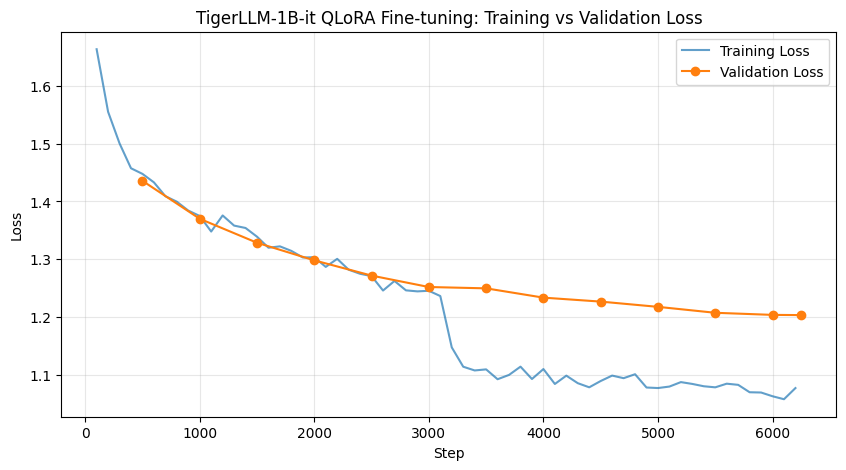

Saved to: /content/drive/MyDrive/Bengali Paraphrasing/checkpoints/tigerllm/loss_curve.png


In [10]:
import matplotlib.pyplot as plt

history = trainer.state.log_history
train_steps, train_losses = [], []
eval_steps, eval_losses = [], []

for entry in history:
    if 'loss' in entry and 'eval_loss' not in entry:
        train_steps.append(entry['step'])
        train_losses.append(entry['loss'])
    if 'eval_loss' in entry:
        eval_steps.append(entry['step'])
        eval_losses.append(entry['eval_loss'])

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_losses, label='Training Loss', alpha=0.7)
plt.plot(eval_steps, eval_losses, label='Validation Loss', marker='o')
plt.xlabel('Step')
plt.ylabel('Loss')
plt.title('TigerLLM-1B-it QLoRA Fine-tuning: Training vs Validation Loss')
plt.legend()
plt.grid(alpha=0.3)

plot_path = f'{CHECKPOINT_DIR}/loss_curve.png'
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print("Saved to:", plot_path)

# CELL 12: Qualitative check

In [11]:
model.eval()
INSTRUCTION = "নিচের বাক্যটি ভিন্নভাবে, একই অর্থ বজায় রেখে লিখুন।"
sample_sources = val_df['source'].sample(5, random_state=42).tolist()

for src in sample_sources:
    messages = [{"role": "user", "content": f"{INSTRUCTION}\n\n{src}"}]
    prompt_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt_text, return_tensors="pt").to(device)
    with torch.no_grad():
        output_ids = model.generate(**inputs, max_new_tokens=100, do_sample=False)
    generated = tokenizer.decode(output_ids[0][inputs['input_ids'].shape[1]:], skip_special_tokens=True)
    print(f"SOURCE:    {src}")
    print(f"GENERATED: {generated}")
    print("-" * 60)
model.train()

[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


SOURCE:    আর রেলওয়ের গেটম্যান মাহফুজ বললেন, ছোটখাট দুর্ঘটনা ঘটে প্রায়ই।
GENERATED: আর রেলওয়ে গেটম্যান মাহফুজ বলেন, ছোটখাট দুর্ঘটনা প্রায়ই ঘটে থাকে।
------------------------------------------------------------


[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


SOURCE:    তার মুখও ঢাকা রয়েছে ছবিটিতে।
GENERATED: ছবিতে তার মুখও রয়েছে।
------------------------------------------------------------


[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


SOURCE:    শীতের দেশের বহু মানুষ মনে করছেন, ভারী বরফ পড়লে হয়তো করোনাভাইরাস টিকবে না। ভুল।
GENERATED: শীতের অনেক লোক মনে করে যে, ভারী বরফ যদি করোনা ভাইরাসকে প্রতিরোধ করতে না পারে, তাহলে এটা হয়তো টিকতে পারবে না।
------------------------------------------------------------


[transformers] Both `max_new_tokens` (=100) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


SOURCE:    আহমেদ ইমতিয়াজের বর্ণাঢ্য এই সঙ্গীতজীবনের ঠিক ভিন্নরূপ ছিল তার ব্যক্তিগত জীবন।
GENERATED: আহমেদ ইমতিয়াজের বর্ণাঢ্য সঙ্গীত জীবনের সম্পূর্ণ বিপরীত ছিল তাঁর ব্যক্তিগত জীবন।
------------------------------------------------------------
SOURCE:    অনেকে মনে করতে থাকে তাঁর উপর কোনো খারাপ আত্মা ভর করেছে, রাতের বেলায় তিনি মেয়েদের রক্ত পান করেন।
GENERATED: অনেকে মনে করে যে, রাতের বেলা তিনি মেয়েদের রক্ত পান করেন, কারণ তিনি খারাপ আত্মা দ্বারা আক্রান্ত হন।
------------------------------------------------------------


PeftModelForCausalLM(
  (base_model): LoraModel(
    (model): Gemma3ForCausalLM(
      (model): Gemma3TextModel(
        (embed_tokens): Gemma3TextScaledWordEmbedding(262144, 1152, padding_idx=0)
        (layers): ModuleList(
          (0-25): 26 x Gemma3DecoderLayer(
            (self_attn): Gemma3Attention(
              (q_proj): lora.Linear4bit(
                (base_layer): Linear4bit(in_features=1152, out_features=1024, bias=False)
                (lora_dropout): ModuleDict(
                  (default): Dropout(p=0.05, inplace=False)
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=1152, out_features=16, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_features=16, out_features=1024, bias=False)
                )
                (lora_embedding_A): ParameterDict()
                (lora_embedding_B): ParameterDict()
                (lora_magnitude_vector): ModuleDict()


# CELL 13: Training summary JSON

In [12]:
import json

training_summary = {
    "model": "md-nishat-008/TigerLLM-1B-it",
    "method": "QLoRA (4-bit, LoRA r=16, alpha=32)",
    "dataset": "BanglaParaphrase subset (100,000 train pairs) - same subset as IndicBARTSS/BanglaT5",
    "max_length": 160,
    "epochs": 2,
    "final_step": 6250,
    "final_validation_loss": 1.203630,
    "note": "Training resumed multiple times across sessions; TrainOutput's summary train_loss field is unreliable due to multi-session resume averaging -- use logged per-step validation loss instead.",
}

summary_path = f'{CHECKPOINT_DIR}/training_summary.json'
with open(summary_path, 'w', encoding='utf-8') as f:
    json.dump(training_summary, f, ensure_ascii=False, indent=2)
print(json.dumps(training_summary, ensure_ascii=False, indent=2))

{
  "model": "md-nishat-008/TigerLLM-1B-it",
  "method": "QLoRA (4-bit, LoRA r=16, alpha=32)",
  "dataset": "BanglaParaphrase subset (100,000 train pairs) - same subset as IndicBARTSS/BanglaT5",
  "max_length": 160,
  "epochs": 2,
  "final_step": 6250,
  "final_validation_loss": 1.20363,
  "note": "Training resumed multiple times across sessions; TrainOutput's summary train_loss field is unreliable due to multi-session resume averaging -- use logged per-step validation loss instead."
}


# CELL 14: Reload verification

In [13]:
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

verify_tokenizer = AutoTokenizer.from_pretrained(best_model_path)
base_verify = AutoModelForCausalLM.from_pretrained(BASE_MODEL_CACHE, quantization_config=bnb_config, device_map={"": 0})
verify_model = PeftModel.from_pretrained(base_verify, best_model_path)
print("Reload check passed -- TigerLLM best_model/ is complete and loadable independently.")

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

Reload check passed -- TigerLLM best_model/ is complete and loadable independently.
